<a href="https://colab.research.google.com/github/ankitaguptacs24-ai/BIS/blob/main/parallel_cellular.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Image loaded successfully: (1086, 1448)


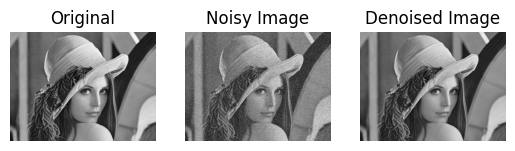

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread(list(uploaded.keys())[0], 0)

if img is None:
    raise ValueError("Image could not be loaded!")

print("Image loaded successfully:", img.shape)

# Add salt-and-pepper noise
noisy = img.copy()
noise = np.random.rand(*img.shape)
noisy[noise < 0.1] = 0
noisy[noise > 0.9] = 255

# Cellular Automata denoising
def cellular_denoise(image):
    result = image.copy()
    rows, cols = image.shape

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):

            # Detect noisy pixels
            if image[i, j] == 0 or image[i, j] == 255:

                # Get 3x3 neighbourhood
                region = image[i-1:i+2, j-1:j+2]
                neighbors = region.flatten()
                neighbors = neighbors[
                    (neighbors != 0) & (neighbors != 255)
                ]

                # Extend neighbourhood if needed
                if len(neighbors) < 3:
                    r1, r2 = max(0, i-2), min(rows, i+3)
                    c1, c2 = max(0, j-2), min(cols, j+3)
                    region = image[r1:r2, c1:c2]
                    neighbors = region.flatten()
                    neighbors = neighbors[
                        (neighbors != 0) & (neighbors != 255)
                    ]

                if len(neighbors) > 0:
                    result[i, j] = np.median(neighbors)

    return result

# Apply denoising
filtered = cellular_denoise(noisy)

# Display results
titles = ["Original", "Noisy Image", "Denoised Image"]
images = [img, noisy, filtered]

for k in range(3):
    plt.subplot(1, 3, k+1)
    plt.imshow(images[k], cmap="gray")
    plt.title(titles[k])
    plt.axis("off")

plt.show()


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Classic Grayscale Lena Portrait.png to Classic Grayscale Lena Portrait.png
